# 09 — Mejora de features y estabilidad temporal

Objetivos:
- Evaluar el aporte de asignaturas cursadas, inscripciones a finales y finales aprobados.
- Comparar la logística y LightGBM con año, con y sin esos tres recuentos.
- Comprobar si la mejora se repite al predecir 2022 y 2023.
- Comparar discriminación y detección para una misma capacidad de atención.

Se mantienen las features preparadas, el target, los folds por estudiante y los hiperparámetros anteriores. Las variables nuevas se incorporan solo en las matrices experimentales de este notebook.

| Año evaluado | Último año de entrenamiento | Años que determinan el resultado evaluado |
|---|---:|---|
| 2022 | 2020 | 2023 y 2024 |
| 2023 | 2021 | 2024 y 2025 |

Ejecutar todas las celdas en orden desde un kernel nuevo. Se realizan 40 ajustes: cuatro escenarios, dos años y cinco folds.

**Alcance:** esta es una última ronda acotada de mejora de variables. Ambos años ya fueron inspeccionados, por lo que la evaluación es exploratoria. No se modifica la configuración, no se publica un modelo final y no se optimizan hiperparámetros ni umbrales sobre estos resultados. Las capacidades de atención son ejemplos pendientes de confirmación institucional.


## 1. Entorno, imports y parámetros del experimento

Se reutilizan las dependencias y el kernel de los notebooks anteriores. El corte de seguimiento se lee de la configuración, sin modificarla.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import sklearn
import lightgbm

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
)
from lightgbm import LGBMClassifier

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir(), (
    f"No se encontró la raíz del proyecto desde {PROJ_ROOT}"
)

os.chdir(PROJ_ROOT)

if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import FEATURES_COLS

with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

SEED = int(config["random_seed"])
VENTANA = int(config["target"]["ventana_anios"])
ANIOS_EVALUACION = [2022, 2023]
UMBRAL = 0.50

CLAVES = ["id_alumno", "anio_academico"]
RECUENTOS = [
    "asignaturas_cursadas",
    "inscripciones_finales",
    "finales_aprobados",
]

CAPACIDADES = [50, 100, 150, 200, 250, 300]
CAPACIDAD_EJEMPLO = 150

CARPETA_REPORTES = PROJ_ROOT / "reports"

assert max(ANIOS_EVALUACION) + VENTANA <= int(
    config["target"]["censurar_hasta"]
)
assert CAPACIDAD_EJEMPLO in CAPACIDADES

print("Proyecto:", PROJ_ROOT)
print("Años evaluados:", ANIOS_EVALUACION)
print("scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)


Proyecto: /Users/alejo/Desktop/alerta-temprana-desercion
Años evaluados: [2022, 2023]
scikit-learn: 1.9.1
LightGBM: 4.7.0


## 2. Carga del dataset y recuperación de los folds

El target y las features se consumen tal como quedaron preparados. Se recupera la asignación por estudiante del notebook 05 para mantener la comparación.


In [2]:
df = (
    load_processed()
    .sort_values(CLAVES)
    .reset_index(drop=True)
)

referencia = pd.read_csv(
    PROJ_ROOT / "reports" / "predicciones_baseline_oof.csv"
)

assert not df.duplicated(CLAVES).any()
assert not referencia.duplicated(CLAVES).any()
assert len(df) == len(referencia)

referencia = referencia[
    CLAVES + ["fold", "abandono_real"]
].rename(columns={"abandono_real": "target_referencia"})

df = df.merge(
    referencia,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert df[["fold", "target_referencia"]].notna().all().all()
assert df["abandono"].isin([0, 1]).all()
assert df["abandono"].astype(int).eq(df["target_referencia"]).all()

df["fold"] = df["fold"].astype(int)

assert df.groupby("id_alumno")["fold"].nunique().eq(1).all()
assert df["fold"].nunique() == int(config["split"]["n_splits"])

print("Registros:", len(df))
print("Estudiantes:", df["id_alumno"].nunique())


Registros: 1979
Estudiantes: 1019


## 3. Preparación de la edad dentro de la validación

Se identifican las edades originalmente iguales a cero para que la imputación se aprenda únicamente con cada entrenamiento. El parquet no se sobrescribe.


In [3]:
edades_originales = load_raw()[
    CLAVES + ["edad"]
].rename(columns={"edad": "edad_original"})

df = df.merge(
    edades_originales,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
).reset_index(drop=True)

assert df["edad_original"].notna().all()

df["edad"] = df["edad"].astype(float)
df.loc[df["edad_original"].eq(0), "edad"] = np.nan

y = df["abandono"].astype(int)

print("Edades pendientes de imputación:", df["edad"].isna().sum())


Edades pendientes de imputación: 3


## 4. Revisión de los tres recuentos académicos

Las cantidades complementan las tasas: una aprobación de cero puede corresponder a distintas cargas académicas. Se usan valores del año de la observación; su disponibilidad histórica debe mantenerse en producción. No se incorpora información de los años utilizados para construir el target.


In [4]:
assert set(RECUENTOS).issubset(df.columns)
assert set(RECUENTOS).isdisjoint(FEATURES_COLS)

columnas_revision = list(dict.fromkeys(
    FEATURES_COLS + ["anio_academico"] + RECUENTOS
))

assert all(
    pd.api.types.is_numeric_dtype(df[col])
    for col in columnas_revision
)
assert not np.isinf(
    df[columnas_revision].to_numpy(dtype=float)
).any()
assert df[RECUENTOS].notna().all().all()
assert df[RECUENTOS].ge(0).all().all()

display(df[RECUENTOS].describe())

carga_cero = (
    df["tasa_aprobacion_asignaturas"].eq(0)
    .groupby(df["asignaturas_cursadas"])
    .agg(["size", "sum"])
    .rename(columns={
        "size": "registros",
        "sum": "registros_tasa_aprobacion_cero",
    })
)
display(carga_cero)


,asignaturas_cursadas,inscripciones_finales,finales_aprobados
count,1979.000000,1979.000000,1979.000000
mean,3.926731,2.345629,1.816574
std,1.939215,2.148857,1.893848
min,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000
50%,4.000000,2.000000,1.000000
75%,5.000000,4.000000,3.000000
max,11.000000,12.000000,8.000000


,registros,registros_tasa_aprobacion_cero
asignaturas_cursadas,,
0,44,44
1,175,91
2,283,118
3,304,86
4,493,169
5,247,65
6,192,26
7,186,6
8,43,2


## 5. Particiones temporales con separación por estudiante

Para evaluar un año se entrena solo con observaciones cuya ventana de dos años ya habría terminado en ese momento. También se excluyen del entrenamiento todos los estudiantes del fold evaluado. Son pruebas de futuro en estudiantes separados, no de seguimiento de alumnos vistos al entrenar.


In [5]:
particiones_temporales = []
filas = []

for anio in ANIOS_EVALUACION:
    ultimo_anio_train = anio - VENTANA

    for fold in sorted(df["fold"].unique()):
        mascara_train = (
            df["anio_academico"].le(ultimo_anio_train)
            & df["fold"].ne(fold)
        )
        mascara_valid = (
            df["anio_academico"].eq(anio)
            & df["fold"].eq(fold)
        )

        idx_train = np.flatnonzero(mascara_train.to_numpy())
        idx_valid = np.flatnonzero(mascara_valid.to_numpy())

        assert len(idx_train) > 0 and len(idx_valid) > 0
        assert y.iloc[idx_train].nunique() == 2
        assert y.iloc[idx_valid].nunique() == 2

        alumnos_train = set(df.iloc[idx_train]["id_alumno"])
        alumnos_valid = set(df.iloc[idx_valid]["id_alumno"])
        assert alumnos_train.isdisjoint(alumnos_valid)

        assert (
            df.iloc[idx_train]["anio_academico"] + VENTANA
        ).le(anio).all()

        particiones_temporales.append({
            "anio": anio,
            "fold": int(fold),
            "idx_train": idx_train,
            "idx_valid": idx_valid,
        })

        filas.append({
            "anio_evaluacion": anio,
            "fold": int(fold),
            "ultimo_anio_train": ultimo_anio_train,
            "registros_train": len(idx_train),
            "estudiantes_train": len(alumnos_train),
            "registros_valid": len(idx_valid),
            "positivos_valid": int(y.iloc[idx_valid].sum()),
        })

resumen_particiones = pd.DataFrame(filas)

assert len(particiones_temporales) == (
    len(ANIOS_EVALUACION) * int(config["split"]["n_splits"])
)

display(resumen_particiones)


,anio_evaluacion,fold,ultimo_anio_train,registros_train,estudiantes_train,registros_valid,positivos_valid
0,2022,1,2020,539,234,82,19
1,2022,2,2020,552,238,85,21
2,2022,3,2020,542,235,83,26
3,2022,4,2020,542,237,85,25
4,2022,5,2020,545,240,86,25
5,2023,1,2021,776,395,121,31
6,2023,2,2021,778,390,120,24
7,2023,3,2021,771,389,115,31
8,2023,4,2021,775,391,117,40
9,2023,5,2021,776,395,116,26


## 6. Cuatro escenarios con hiperparámetros fijos

La logística mantiene sus trece variables como referencia; LightGBM conserva el año como en el notebook 07. Cada familia se compara con su propia variante que incorpora los tres recuentos. Se mantienen la imputación dentro del entrenamiento y el escalado para logística.


In [6]:
logistica = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

lightgbm_anio = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("modelo", LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=7,
        max_depth=3,
        min_child_samples=30,
        reg_lambda=1.0,
        class_weight=None,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )),
])

experimentos = {
    "logistica_base": {
        "pipeline": logistica,
        "columnas": list(FEATURES_COLS),
    },
    "logistica_recuentos": {
        "pipeline": clone(logistica),
        "columnas": list(FEATURES_COLS) + RECUENTOS,
    },
    "lightgbm_anio": {
        "pipeline": lightgbm_anio,
        "columnas": list(FEATURES_COLS) + ["anio_academico"],
    },
    "lightgbm_anio_recuentos": {
        "pipeline": clone(lightgbm_anio),
        "columnas": list(FEATURES_COLS) + ["anio_academico"] + RECUENTOS,
    },
}

for nombre, especificacion in experimentos.items():
    columnas = especificacion["columnas"]
    assert len(columnas) == len(set(columnas))
    assert not {
        "id_alumno", "abandono", "prox_actividad", "target_referencia"
    }.intersection(columnas)
    print(nombre, "—", len(columnas), "predictores")

print(
    "Entrenamientos:",
    len(experimentos) * len(particiones_temporales),
)


logistica_base — 13 predictores
logistica_recuentos — 16 predictores
lightgbm_anio — 14 predictores
lightgbm_anio_recuentos — 17 predictores
Entrenamientos: 40


## 7. Entrenamiento y predicciones fuera de muestra

Cada escenario se ajusta por separado en cada año y fold. No se usan las etiquetas de evaluación para ajustar el pipeline, elegir iteraciones ni seleccionar variables dentro del entrenamiento.


In [7]:
bloques_predicciones = []

for nombre, especificacion in experimentos.items():
    X_actual = df[especificacion["columnas"]].copy()

    for anio in ANIOS_EVALUACION:
        probabilidades = np.full(len(df), np.nan)
        veces_evaluado = np.zeros(len(df), dtype=int)

        for particion in particiones_temporales:
            if particion["anio"] != anio:
                continue

            idx_train = particion["idx_train"]
            idx_valid = particion["idx_valid"]

            modelo_fold = clone(especificacion["pipeline"])
            modelo_fold.fit(
                X_actual.iloc[idx_train],
                y.iloc[idx_train],
            )

            probabilidades[idx_valid] = modelo_fold.predict_proba(
                X_actual.iloc[idx_valid]
            )[:, 1]

            veces_evaluado[idx_valid] += 1

        mascara_evaluacion = df["anio_academico"].eq(anio)
        posiciones = mascara_evaluacion.to_numpy()

        assert np.isfinite(probabilidades[posiciones]).all()
        assert (veces_evaluado[posiciones] == 1).all()

        salida = df.loc[
            mascara_evaluacion, CLAVES + ["fold"]
        ].copy()

        salida["modelo"] = nombre
        salida["abandono_real"] = y.loc[
            mascara_evaluacion
        ].to_numpy()
        salida["probabilidad_abandono"] = probabilidades[posiciones]
        salida["ultimo_anio_train"] = anio - VENTANA

        bloques_predicciones.append(salida)
        print(f"{nombre} — evaluación {anio} terminada")

predicciones_mejora = pd.concat(
    bloques_predicciones,
    ignore_index=True,
)

assert not predicciones_mejora.duplicated(
    ["modelo"] + CLAVES
).any()

assert predicciones_mejora.groupby(CLAVES)["modelo"].nunique().eq(
    len(experimentos)
).all()

assert predicciones_mejora.groupby(CLAVES)["abandono_real"].nunique().eq(
    1
).all()

display(
    predicciones_mejora.groupby(
        ["anio_academico", "modelo"]
    ).size().rename("predicciones")
)


logistica_base — evaluación 2022 terminada
logistica_base — evaluación 2023 terminada
logistica_recuentos — evaluación 2022 terminada
logistica_recuentos — evaluación 2023 terminada
lightgbm_anio — evaluación 2022 terminada
lightgbm_anio — evaluación 2023 terminada
lightgbm_anio_recuentos — evaluación 2022 terminada
lightgbm_anio_recuentos — evaluación 2023 terminada


anio_academico  modelo                 
2022            lightgbm_anio              421
                lightgbm_anio_recuentos    421
                logistica_base             421
                logistica_recuentos        421
2023            lightgbm_anio              589
                lightgbm_anio_recuentos    589
                logistica_base             589
                logistica_recuentos        589
Name: predicciones, dtype: int64

## 8. Métricas anuales y por fold

Las métricas anuales agrupan las predicciones de los cinco folds para cada año. El resumen por fold muestra su variación; las desviaciones estándar no son intervalos de confianza. El umbral 0,50 se conserva solo como referencia.


In [8]:
def resumir_alertas(grupo, alertas):
    real = grupo["abandono_real"].to_numpy(dtype=int)
    alertas = np.asarray(alertas, dtype=bool)

    assert alertas.ndim == 1 and len(alertas) == len(real)

    positivos = real == 1
    tp = int((positivos & alertas).sum())
    fp = int((~positivos & alertas).sum())
    fn = int((positivos & ~alertas).sum())
    tn = int((~positivos & ~alertas).sum())

    return {
        "registros": len(grupo),
        "estudiantes": grupo["id_alumno"].nunique(),
        "positivos": int(positivos.sum()),
        "alertas": int(alertas.sum()),
        "verdaderos_positivos": tp,
        "falsos_positivos": fp,
        "falsos_negativos": fn,
        "verdaderos_negativos": tn,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
    }


def evaluar_probabilidades(grupo):
    real = grupo["abandono_real"].astype(int)
    prob = grupo["probabilidad_abandono"]

    return {
        **resumir_alertas(grupo, prob.ge(UMBRAL)),
        "roc_auc": (
            roc_auc_score(real, prob)
            if real.nunique() == 2 else np.nan
        ),
        "average_precision": (
            average_precision_score(real, prob)
            if real.sum() > 0 else np.nan
        ),
    }


filas_folds = []
for (anio, modelo, fold), grupo in predicciones_mejora.groupby(
    ["anio_academico", "modelo", "fold"]
):
    filas_folds.append({
        "anio_evaluacion": int(anio),
        "modelo": modelo,
        "fold": int(fold),
        **evaluar_probabilidades(grupo),
    })

metricas_folds = pd.DataFrame(filas_folds)

filas_anuales = []
for (anio, modelo), grupo in predicciones_mejora.groupby(
    ["anio_academico", "modelo"]
):
    filas_anuales.append({
        "anio_evaluacion": int(anio),
        "modelo": modelo,
        **evaluar_probabilidades(grupo),
    })

metricas_anuales = pd.DataFrame(filas_anuales)

display(
    metricas_anuales[[
        "anio_evaluacion", "modelo", "registros", "positivos",
        "roc_auc", "average_precision", "precision", "recall",
        "alertas", "falsos_negativos",
    ]].round(4)
)

resumen_folds = (
    metricas_folds.groupby(["anio_evaluacion", "modelo"])[
        ["roc_auc", "average_precision", "precision", "recall"]
    ].agg(["mean", "std"])
)

display(resumen_folds.round(4))


,anio_evaluacion,modelo,registros,positivos,roc_auc,average_precision,precision,recall,alertas,falsos_negativos
0,2022,lightgbm_anio,421,116,0.8018,0.7434,0.8125,0.5603,80,51
1,2022,lightgbm_anio_recuentos,421,116,0.8099,0.7543,0.8312,0.5517,77,52
2,2022,logistica_base,421,116,0.8426,0.7188,0.7500,0.5690,88,50
3,2022,logistica_recuentos,421,116,0.8410,0.7246,0.7889,0.6121,90,45
4,2023,lightgbm_anio,589,152,0.7418,0.6045,0.6593,0.3947,91,92
5,2023,lightgbm_anio_recuentos,589,152,0.7453,0.6116,0.6739,0.4079,92,90
6,2023,logistica_base,589,152,0.7770,0.6377,0.7191,0.4211,89,88
7,2023,logistica_recuentos,589,152,0.7782,0.6381,0.7045,0.4079,88,90


roc_auc         average_precision  \
                                           mean     std              mean   
anio_evaluacion modelo                                                      
2022            lightgbm_anio            0.7951  0.0416            0.7461   
                lightgbm_anio_recuentos  0.7998  0.0503            0.7527   
                logistica_base           0.8432  0.0413            0.7477   
                logistica_recuentos      0.8423  0.0334            0.7387   
2023            lightgbm_anio            0.7340  0.0440            0.5955   
                lightgbm_anio_recuentos  0.7362  0.0432            0.6094   
                logistica_base           0.7674  0.0316            0.6357   
                logistica_recuentos      0.7708  0.0363            0.6348   

                                                precision          recall  \
                                            std      mean     std    mean   
anio_evaluacion modelo                                                      
2022            lightgbm_anio            0.0516    0.8225  0.0609  0.5580   
                lightgbm_anio_recuentos  0.0588    0.8401  0.0570  0.5467   
                logistica_base           0.0725    0.7695  0.1410  0.5660   
                logistica_recuentos      0.0700    0.7959  0.0958  0.6069   
2023            lightgbm_anio            0.0809    0.6606  0.0835  0.3953   
                lightgbm_anio_recuentos  0.0714    0.6749  0.0696  0.4068   
                logistica_base           0.0799    0.7164  0.1144  0.4224   
                logistica_recuentos      0.0869    0.6999  0.1313  0.4095   

                                                 
                                            std  
anio_evaluacion modelo                           
2022            lightgbm_anio            0.0592  
                lightgbm_anio_recuentos  0.0806  
                logistica_base           0.0683  
                logistica_recuentos      0.0751  
2023            lightgbm_anio            0.0677  
                lightgbm_anio_recuentos  0.0659  
                logistica_base           0.0485  
                logistica_recuentos      0.0657

## 9. Aporte de los recuentos dentro de cada familia

Se resta la métrica de referencia a la de su variante con recuentos, usando el mismo año y fold. Los valores positivos indican mejora observada en esa métrica; no representan una prueba de significación.


In [9]:
comparaciones = {
    "logistica_recuentos": "logistica_base",
    "lightgbm_anio_recuentos": "lightgbm_anio",
}

metricas_comparar = [
    "roc_auc", "average_precision", "precision", "recall"
]

bloques_diferencias = []

for candidato, referencia_modelo in comparaciones.items():
    nuevas = (
        metricas_folds.loc[metricas_folds["modelo"].eq(candidato)]
        .set_index(["anio_evaluacion", "fold"])[metricas_comparar]
        .sort_index()
    )
    anteriores = (
        metricas_folds.loc[metricas_folds["modelo"].eq(referencia_modelo)]
        .set_index(["anio_evaluacion", "fold"])[metricas_comparar]
        .sort_index()
    )

    assert nuevas.index.equals(anteriores.index)

    diferencias = nuevas - anteriores
    diferencias.columns = [
        f"delta_{columna}" for columna in diferencias.columns
    ]
    diferencias = diferencias.reset_index()
    diferencias["candidato"] = candidato
    diferencias["referencia"] = referencia_modelo

    bloques_diferencias.append(diferencias)

diferencias_folds = pd.concat(
    bloques_diferencias,
    ignore_index=True,
)

display(
    diferencias_folds.groupby(["anio_evaluacion", "candidato"])[[
        "delta_roc_auc",
        "delta_average_precision",
        "delta_precision",
        "delta_recall",
    ]].agg(["mean", "min", "max"]).round(4)
)


delta_roc_auc                  \
                                                 mean     min     max   
anio_evaluacion candidato                                               
2022            lightgbm_anio_recuentos        0.0047 -0.0292  0.0164   
                logistica_recuentos           -0.0008 -0.0126  0.0142   
2023            lightgbm_anio_recuentos        0.0022 -0.0100  0.0228   
                logistica_recuentos            0.0034 -0.0074  0.0197   

                                        delta_average_precision          \
                                                           mean     min   
anio_evaluacion candidato                                                 
2022            lightgbm_anio_recuentos                  0.0066 -0.0102   
                logistica_recuentos                     -0.0090 -0.0174   
2023            lightgbm_anio_recuentos                  0.0140 -0.0046   
                logistica_recuentos                     -0.0009 -0.0192   

                                                delta_precision          \
                                            max            mean     min   
anio_evaluacion candidato                                                 
2022            lightgbm_anio_recuentos  0.0150          0.0176 -0.0167   
                logistica_recuentos      0.0116          0.0265 -0.0769   
2023            lightgbm_anio_recuentos  0.0634          0.0143  0.0000   
                logistica_recuentos      0.0324         -0.0164 -0.0863   

                                                delta_recall                  
                                            max         mean     min     max  
anio_evaluacion candidato                                                     
2022            lightgbm_anio_recuentos  0.0625      -0.0114 -0.0952  0.0385  
                logistica_recuentos      0.0952       0.0409  0.0000  0.0800  
2023            lightgbm_anio_recuentos  0.0368       0.0115  0.0000  0.0323  
                logistica_recuentos      0.0441      -0.0129 -0.0323  0.0000

## 10. Comparación para una misma capacidad de atención

Se ordenan los estudiantes de cada año y escenario por puntuación. Se comparan las mismas cantidades de contactos y se marca si hay empates en el límite. El identificador solo permite reproducir el desempate; no es un predictor ni una política institucional.


In [10]:
filas = []

for (anio, modelo), grupo in predicciones_mejora.groupby(
    ["anio_academico", "modelo"]
):
    ranking = grupo.sort_values(
        ["probabilidad_abandono", "id_alumno"],
        ascending=[False, True],
    )
    assert ranking["id_alumno"].is_unique

    for capacidad in CAPACIDADES:
        cantidad = min(capacidad, len(ranking))
        alertas = np.arange(len(ranking)) < cantidad

        seleccionados = ranking.iloc[:cantidad]
        score_corte = seleccionados["probabilidad_abandono"].iloc[-1]
        empate = (
            ranking["probabilidad_abandono"].eq(score_corte).sum()
            > seleccionados["probabilidad_abandono"].eq(score_corte).sum()
        )

        filas.append({
            "anio_evaluacion": int(anio),
            "modelo": modelo,
            "capacidad": capacidad,
            "score_minimo_seleccionado": score_corte,
            "empate_en_limite": bool(empate),
            **resumir_alertas(ranking, alertas),
        })

metricas_capacidades = pd.DataFrame(filas)

comparacion_capacidad = metricas_capacidades.loc[
    metricas_capacidades["capacidad"].eq(CAPACIDAD_EJEMPLO)
].copy()

display(
    comparacion_capacidad[[
        "anio_evaluacion", "modelo", "alertas",
        "verdaderos_positivos", "falsos_positivos",
        "falsos_negativos", "precision", "recall",
        "empate_en_limite",
    ]].round(4)
)


,anio_evaluacion,modelo,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall,empate_en_limite
2,2022,lightgbm_anio,150,83,67,33,0.5533,0.7155,False
8,2022,lightgbm_anio_recuentos,150,83,67,33,0.5533,0.7155,True
14,2022,logistica_base,150,85,65,31,0.5667,0.7328,False
20,2022,logistica_recuentos,150,87,63,29,0.5800,0.7500,False
26,2023,lightgbm_anio,150,81,69,71,0.5400,0.5329,False
32,2023,lightgbm_anio_recuentos,150,77,73,75,0.5133,0.5066,False
38,2023,logistica_base,150,78,72,74,0.5200,0.5132,False
44,2023,logistica_recuentos,150,81,69,71,0.5400,0.5329,False


## 11. Visualización de la estabilidad entre años

Se comparan Average Precision y recall para la capacidad ilustrativa. Debe revisarse cada año por separado: el número de positivos y el tamaño de evaluación son distintos.


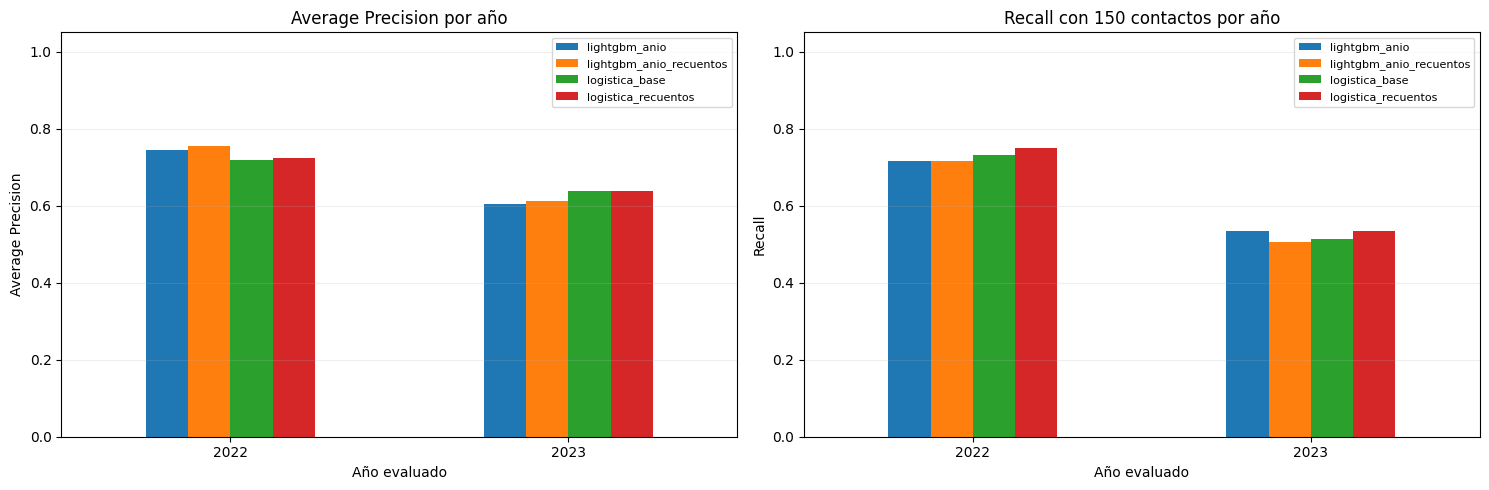

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

metricas_anuales.pivot(
    index="anio_evaluacion",
    columns="modelo",
    values="average_precision",
).plot.bar(ax=axes[0])

comparacion_capacidad.pivot(
    index="anio_evaluacion",
    columns="modelo",
    values="recall",
).plot.bar(ax=axes[1])

axes[0].set_title("Average Precision por año")
axes[0].set_ylabel("Average Precision")

axes[1].set_title(
    f"Recall con {CAPACIDAD_EJEMPLO} contactos por año"
)
axes[1].set_ylabel("Recall")

for ax in axes:
    ax.set_xlabel("Año evaluado")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 12. Guardado de los resultados experimentales

Al ejecutar esta celda se generan cinco CSV nuevos en reports/. No se sobrescriben las predicciones anteriores ni se guarda un modelo final. FEATURES_COLS y configs/features.yaml siguen sin cambios hasta decidir si las variables aportan una mejora útil.


In [12]:
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

reportes = {
    "mejora_features_metricas_folds.csv": metricas_folds,
    "mejora_features_metricas_anuales.csv": metricas_anuales,
    "mejora_features_diferencias_folds.csv": diferencias_folds,
    "mejora_features_capacidades.csv": metricas_capacidades,
    "mejora_features_predicciones.csv": predicciones_mejora,
}

for nombre, datos in reportes.items():
    datos.to_csv(CARPETA_REPORTES / nombre, index=False)
    print("Guardado:", nombre)


Guardado: mejora_features_metricas_folds.csv
Guardado: mejora_features_metricas_anuales.csv
Guardado: mejora_features_diferencias_folds.csv
Guardado: mejora_features_capacidades.csv
Guardado: mejora_features_predicciones.csv


## Conclusiones de la mejora de features

Se evaluaron 421 estudiantes en 2022 y 589 en 2023, conservando la separación temporal y por estudiante. La tabla agrupa las predicciones de cada año; los 150 contactos son un escenario ilustrativo.

| Año | Escenario | Average Precision agrupada | Positivos detectados con 150 contactos |
|---|---|---:|---:|
| 2022 | Logística base | 0,7188 | 85 |
| 2022 | Logística con recuentos | 0,7246 | 87 |
| 2022 | LightGBM con año | 0,7434 | 83 |
| 2022 | LightGBM con año y recuentos | 0,7543 | 83 |
| 2023 | Logística base | 0,6377 | 78 |
| 2023 | Logística con recuentos | 0,6381 | 81 |
| 2023 | LightGBM con año | 0,6045 | 81 |
| 2023 | LightGBM con año y recuentos | 0,6116 | 77 |

- **Logística:** los recuentos agregan dos y tres positivos detectados con 150 contactos en 2022 y 2023. Sin embargo, la Average Precision media entre folds disminuye 0,0090 y 0,0009, respectivamente. El aporte es pequeño y depende del criterio de comparación.
- **LightGBM:** los recuentos mejoran la Average Precision media entre folds en 0,0066 en 2022 y 0,0140 en 2023. Aun así, con 150 contactos no aumentan los positivos detectados en 2022 y reducen cuatro en 2023. Una mejora de ordenación global no garantiza una mejora para una capacidad concreta.
- **Estabilidad:** los resultados agrupados y las medias entre folds no son equivalentes. El beneficio observado no es uniforme entre años, modelos y métricas, y no demuestra superioridad estadística.

**Decisión provisional:** no adoptar automáticamente los tres recuentos en todos los modelos. Si el criterio operativo fueran 150 contactos, la logística con recuentos merece continuar como candidata; esa capacidad todavía debe confirmarse. Conservar las referencias y cerrar la elección según detección, falsas alertas, estabilidad y complejidad, antes de calibrar y explicar el candidato elegido.

Ambos años ya fueron inspeccionados: esta ronda es exploratoria, no un test independiente. No se fijó un umbral definitivo ni se guardó un modelo final. Si cambian los datos o los resultados, deben actualizarse estas conclusiones.
